# Refined products demand — 01 Data pipeline

**Purpose.** Take five public sources from their raw files to one point-in-time modelling dataset per product (US gasoline, US distillate fuel oil, Singapore bunker fuel oil), and show for every variable where it comes from, how it was processed and from when it could legitimately be used. Notebook 02 only reads the tables this pipeline writes.

**Run order.** `python -m src.download` (optional, refreshes the raw files) → this notebook → `python -m src.model` (the backtests, about 50 minutes) → `02_model.ipynb`. The two build cells below are the same as `python -m src.sql` and `python -m src.data`.

| Step | Where | Output |
|---|---|---|
| Ingestion | `src/download.py` | `data/<product>/*.csv`, as published |
| Raw layer | `src/sql.py` | DuckDB table `raw`: every observation, every vintage seen |
| Clean layer | `src/sql.py` | DuckDB tables `demand`, `predictors`, `catalog` |
| Alignment | `src/data.py` | DuckDB table `panel`, read by `src/model.py` and notebook 02 |

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd

from src import config as c, data, sql

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.figsize": (10, 3), "axes.grid": True, "grid.alpha": .3})

## 1. Ingestion: raw files into DuckDB

`sql.build()` appends to `raw` whatever the files hold that the table does not: new observations and revised values, each stamped with `ingested_at`, the time its file was downloaded. Nothing is ever updated or deleted, so the load is idempotent and a revision is kept next to the value it replaces.

In [2]:
sql.build()  # every file was already loaded: nothing to add

      0 rows added to raw from US_gasoline/eia_monthly.csv
      0 rows added to raw from US_gasoline/eia_weekly.csv
      0 rows added to raw from US_gasoline/fred.csv
      0 rows added to raw from US_distillate_fuel_oil/eia_monthly.csv
      0 rows added to raw from US_distillate_fuel_oil/eia_weekly.csv
      0 rows added to raw from US_distillate_fuel_oil/fred.csv
      0 rows added to raw from US_distillate_fuel_oil/noaa_hdd.csv
      0 rows added to raw from SGP_bunker_fuel_oil/mpa_bunker_sales.csv
      0 rows added to raw from SGP_bunker_fuel_oil/mpa_vessel_calls.csv
      0 rows added to raw from SGP_bunker_fuel_oil/mpa_cargo.csv
      0 rows added to raw from SGP_bunker_fuel_oil/mpa_tankers.csv
      0 rows added to raw from SGP_bunker_fuel_oil/cpb_world_trade.csv


In [3]:
sql.query("DESCRIBE raw")[["column_name", "column_type"]]

,column_name,column_type
0,file,VARCHAR
1,series,VARCHAR
2,obs_date,DATE
3,value,DOUBLE
4,ingested_at,TIMESTAMP


In [4]:
# two downloads so far: the first load, then one month of new and revised observations
sql.query("""
    SELECT CAST(ingested_at AS DATE) AS ingested, COUNT(DISTINCT file) AS files, COUNT(*) AS observations,
           MAX(obs_date) AS newest_observation
    FROM raw GROUP BY 1 ORDER BY 1
""")

,ingested,files,observations,newest_observation
0,2026-10-10,12,31506,2026-10-02
1,2026-11-15,12,442,2026-11-06


## 2. Sources and conventions

`catalog` is the data dictionary, stored next to the data. The publication lag is the one number the model depends on; it lives in `config.py` and is added here.

In [5]:
catalog = sql.query("SELECT * FROM catalog")
catalog[["product", "variable", "source", "source_id", "definition", "unit"]]

,product,variable,source,source_id,definition,unit
0,gasoline,demand,EIA Petroleum Supply Monthly,MGFUPUS2,Finished motor gasoline product supplied,kb/d
1,gasoline,exports,EIA Petroleum Supply Monthly,MGFEXUS2,Finished motor gasoline exports (context only),kb/d
2,gasoline,retail_price,EIA Gasoline and Diesel Fuel Update,EMM_EPMR_PTE_NUS_DPG,Regular gasoline retail price,USD/gal
3,gasoline,product_supplied_weekly,EIA Weekly Petroleum Status Report,WGFUPUS2,Finished motor gasoline product supplied (weekly estimate),kb/d
4,gasoline,stocks,EIA Weekly Petroleum Status Report,WGTSTUS1,Total gasoline stocks (context only),thousand barrels
5,gasoline,vmt,FHWA Traffic Volume Trends via FRED,TRFVOLUSM227NFWA,Vehicle miles travelled (not seasonally adjusted),million miles
6,gasoline,payrolls,BLS Employment Situation via FRED,PAYEMS,Total nonfarm payrolls (seasonally adjusted),thousand persons
7,gasoline,inc,BEA Personal Income and Outlays via FRED,DSPIC96,Real disposable personal income (seasonally adjusted annual rate),billion chained 2017 USD
8,gasoline,cpi,BLS Consumer Price Index via FRED,CPIAUCSL,CPI all urban consumers all items (seasonally adjusted),index 1982-84=100
9,distillate,demand,EIA Petroleum Supply Monthly,MDIUPUS2,Distillate fuel oil product supplied,kb/d


In [6]:
lag = {"gasoline": c.DEMAND_LAG["gasoline"], "distillate": c.DEMAND_LAG["distillate"], "bunker": c.DEMAND_LAG["bunker"]}
catalog["lag_months"] = catalog["variable"].map(c.LAG).fillna(catalog["product"].map(lag).where(catalog["variable"] == "demand"))
catalog[["product", "variable", "frequency", "date_stamp", "release", "lag_months"]]

,product,variable,frequency,date_stamp,release,lag_months
0,gasoline,demand,monthly,15th of the month,end of the second month after,2.00
1,gasoline,exports,monthly,15th of the month,end of the second month after,NaN
2,gasoline,retail_price,monthly,15th of the month,weekly survey so known at month end,NaN
3,gasoline,product_supplied_weekly,weekly,Friday ending the week,Wednesday after the week,NaN
4,gasoline,stocks,weekly,Friday ending the week,Wednesday after the week,NaN
5,gasoline,vmt,monthly,1st of the month,about five weeks after the month,2.00
6,gasoline,payrolls,monthly,1st of the month,first Friday of the following month,1.00
7,gasoline,inc,monthly,1st of the month,end of the following month,1.00
8,gasoline,cpi,monthly,1st of the month,mid following month,NaN
9,distillate,demand,monthly,15th of the month,end of the second month after,2.00


Rows without a lag are not model inputs on their own: `retail_price` and `cpi` are combined into `real_price` (lag 1), the weekly product supplied becomes a four-week average (available six days after the week), and exports and stocks are kept as context only.

Four dates are kept apart throughout:

- **Observation date** — `period_end`, the last day of the period the number describes.
- **Availability date** — `available_at`, when the number was published: `period_end` plus the source's lag. This is the date every join uses.
- **Ingestion date** — `ingested_at`, when the file entered this database.
- **Vintage** — which version of a revised number. The sources publish only their latest version, so the database holds vintages only from its first download on (section 5).

## 3. Clean layer

`demand` and `predictors` are rebuilt from the latest value of every raw observation. Cleaning is limited to standardisation: one date convention (`period_end`), one name per variable, a daily rate for the Singapore target. No value is filled, smoothed or removed.

In [7]:
sql.query("""
    SELECT product, unit, MIN(period_end) AS first, MAX(period_end) AS last, COUNT(*) AS months
    FROM demand GROUP BY 1, 2 ORDER BY 1
""")

,product,unit,first,last,months
0,bunker,kt/d,1995-01-31,2026-09-30,381
1,distillate,kb/d,1945-01-31,2026-08-31,980
2,gasoline,kb/d,1945-01-31,2026-08-31,980


In [8]:
sql.query("""
    SELECT product, variable, MIN(period_end) AS first, MAX(period_end) AS last, COUNT(*) AS observations
    FROM predictors GROUP BY 1, 2 ORDER BY 1, 2
""")

,product,variable,first,last,observations
0,bunker,bunker_calls,1993-01-31,2026-09-30,405
1,bunker,bunker_calls_gt,1993-01-31,2026-09-30,405
2,bunker,cargo,1995-01-31,2026-09-30,381
3,bunker,tankers,2002-01-31,2026-09-30,297
4,bunker,wtr,2000-01-31,2026-08-31,320
5,distillate,cpi,1947-01-31,2026-10-31,957
6,distillate,exports,1945-01-31,2026-08-31,980
7,distillate,hdd,1997-05-31,2026-10-31,354
8,distillate,hdd_oil,1997-05-31,2026-10-31,354
9,distillate,ind,1919-01-31,2026-09-30,1293


In [9]:
# the Singapore target: monthly sales of the six fuel-oil grades, over the days in the month so that
# February is not a demand drop and the unit is a daily rate like EIA's
sql.query("""
    SELECT period_end, value * day(period_end) AS kt_month, value AS kt_day
    FROM demand WHERE product = 'bunker' AND period_end BETWEEN DATE '2026-01-01' AND DATE '2026-04-30'
    ORDER BY period_end
""")

,period_end,kt_month,kt_day
0,2026-01-31,"4,781.11",154.23
1,2026-02-28,"4,236.56",151.31
2,2026-03-31,"4,364.85",140.80
3,2026-04-30,"4,047.56",134.92


In [10]:
# back to million tonnes a year. MPA's headline totals, 54.9 Mt in 2024 and 56.8 Mt in 2025, also count
# gasoil and LNG, which the fuel-oil target leaves out
sql.query("""
    SELECT YEAR(period_end) AS year, SUM(value * day(period_end)) / 1000 AS fuel_oil_mt
    FROM demand WHERE product = 'bunker' AND YEAR(period_end) IN (2024, 2025) GROUP BY 1 ORDER BY 1
""")

,year,fuel_oil_mt
0,2024,50.60
1,2025,51.89


## 4. Validation of the clean tables

In [11]:
# keys, missing values, impossible values, over the sample the model uses (2000 on).
# The primary keys already forbid duplicates
sql.query(f"""
    SELECT 'demand' AS table_name, COUNT(*) AS rows, COUNT(*) - COUNT(DISTINCT (product, period_end)) AS duplicates,
           COUNT(*) FILTER (WHERE value IS NULL) AS missing, COUNT(*) FILTER (WHERE value <= 0) AS not_positive
    FROM demand WHERE period_end >= DATE '{c.SAMPLE_START}'
    UNION ALL
    SELECT 'predictors', COUNT(*), COUNT(*) - COUNT(DISTINCT (product, variable, period_end)),
           COUNT(*) FILTER (WHERE value IS NULL), COUNT(*) FILTER (WHERE value <= 0)
    FROM predictors WHERE period_end >= DATE '{c.SAMPLE_START}'
""")

,table_name,rows,duplicates,missing,not_positive
0,demand,961,0,0,0
1,predictors,11679,0,0,0


In [12]:
# frequency: days between consecutive observations of each series, since 2000
gaps = sql.query("""
    SELECT product, variable, period_end,
           period_end - LAG(period_end) OVER (PARTITION BY product, variable ORDER BY period_end) AS gap_days
    FROM (SELECT product, variable, period_end FROM predictors
          UNION ALL SELECT product, 'demand', period_end FROM demand)
    WHERE period_end >= DATE '2000-01-01'
""")
frequency = gaps.groupby(["product", "variable"])["gap_days"].agg(["median", "max"])
frequency.value_counts().rename("series").reset_index()

,median,max,series
0,31.00,31,20
1,7.00,7,4
2,31.00,61,2


In [13]:
# the series behind the odd line: the observation that follows a hole in a monthly series
gaps[(gaps["gap_days"] > 31)]

,product,variable,period_end,gap_days
2210,distillate,cpi,2025-11-30,61
3932,gasoline,cpi,2025-11-30,61


Every series has the frequency the catalog states, weekly or monthly, with one hole: the source holds no CPI for October 2025. Nothing is interpolated in the clean table. Downstream, `real_price` has no October 2025 value either, so the alignment carries September's for one more month, inside the staleness tolerance (section 7).

In [14]:
# suspicious values: the largest month-on-month moves of each target, in %
moves = sql.query("""
    SELECT product, period_end, value,
           100 * (value / LAG(value) OVER (PARTITION BY product ORDER BY period_end) - 1) AS move_pct
    FROM demand WHERE period_end >= DATE '2000-01-01'
""")
moves.loc[moves["move_pct"].abs().sort_values(ascending=False).index].groupby("product").head(3).sort_values(["product", "period_end"])

,product,period_end,value,move_pct
405,bunker,2007-02-28,90.44,31.88
411,bunker,2007-08-31,89.94,17.11
491,bunker,2014-04-30,122.89,23.58
797,distillate,2013-01-31,"4,062.00",15.10
857,distillate,2018-01-31,"4,491.00",12.98
924,distillate,2023-08-31,"4,052.00",13.09
243,gasoline,2020-04-30,"5,866.00",-24.59
244,gasoline,2020-05-31,"7,198.00",22.71
245,gasoline,2020-06-30,"8,292.00",15.20


The US moves are the spring of 2020: real, kept in the data, and handled in the model (`EXCLUDE_YEARS`). The Singapore moves of 2007 and 2014 are single months in a volatile port series; with no second source to check them against they are kept as published.

In [15]:
# cross-check between two EIA products: the weekly estimate averaged over each month against the monthly
# figure published two months later, absolute gap in %
check = sql.query("""
    SELECT d.product, d.period_end, d.value AS monthly, w.weekly
    FROM demand d
    JOIN (SELECT product, last_day(period_end) AS period_end, AVG(value) AS weekly
          FROM predictors WHERE variable = 'product_supplied_weekly' GROUP BY 1, 2) w
      ON d.product = w.product AND d.period_end = w.period_end
    WHERE d.period_end >= DATE '2000-01-01'
""")
check["gap_pct"] = 100 * (check["weekly"] / check["monthly"] - 1).abs()
check.groupby("product")["gap_pct"].describe()[["count", "mean", "50%", "max"]]

,count,mean,50%,max
product,,,,
distillate,320.00,3.51,2.75,16.14
gasoline,320.00,1.45,1.18,11.33


The weekly series is the same concept as the target, known two months earlier: on average within 1.5% of the monthly figure for gasoline and 3.5% for distillate. That makes it a legitimate nowcast input, noisier for distillate, and the main reason a model might beat a naive forecast at short horizons.

## 5. Point-in-time: publication lags and revisions

**Lags.** A number cannot be used before it is published. Each series gets `available_at = period_end + lag`, with the lag read off the source's release calendar (section 2) and rounded up to a month end.

In [16]:
# July's truck tonnage came out on 1 October: lag 3
truck = sql.query("SELECT period_end, value FROM predictors WHERE variable = 'truck' ORDER BY period_end")
truck["available_at"] = truck["period_end"] + pd.offsets.MonthEnd(c.LAG["truck"])
truck.tail(3)

,period_end,value,available_at
317,2026-06-30,114.40,2026-09-30
318,2026-07-31,113.20,2026-10-31
319,2026-08-31,112.80,2026-11-30


**Are the lags right?** They can be tested against a real download. At the time of the latest ingestion, the convention says which period of each series should already be published; the file says which period actually was. The convention must never be ahead of the file.

In [17]:
ingested = sql.query("SELECT MAX(ingested_at) AS t FROM raw")["t"].iloc[0]
origin = ingested.normalize() - pd.offsets.MonthEnd(1)  # the last month end before the download

newest = sql.query("""
    SELECT product, variable, MAX(period_end) AS newest_on_file FROM predictors GROUP BY 1, 2
    UNION ALL SELECT product, 'demand', MAX(period_end) FROM demand GROUP BY 1
""")
newest["lag_months"] = newest["variable"].map(c.LAG).fillna(newest["product"].map(lag).where(newest["variable"] == "demand"))
newest = newest.dropna(subset="lag_months")
newest["convention_allows"] = [origin - pd.offsets.MonthEnd(k) for k in newest["lag_months"]]
newest["months_in_hand"] = ((newest["newest_on_file"] - newest["convention_allows"]).dt.days / 30.4).round().astype(int)
assert (newest["newest_on_file"] >= newest["convention_allows"]).all()  # no lag is too short
print(f"downloaded {ingested:%d %b %Y}, forecast origin {origin:%d %b %Y}")
newest.sort_values(["product", "variable"]).reset_index(drop=True)

downloaded 15 Nov 2026, forecast origin 31 Oct 2026


,product,variable,newest_on_file,lag_months,convention_allows,months_in_hand
0,bunker,bunker_calls,2026-09-30,1.00,2026-09-30,0
1,bunker,bunker_calls_gt,2026-09-30,1.00,2026-09-30,0
2,bunker,cargo,2026-09-30,1.00,2026-09-30,0
3,bunker,demand,2026-09-30,1.00,2026-09-30,0
4,bunker,tankers,2026-09-30,1.00,2026-09-30,0
5,bunker,wtr,2026-08-31,2.00,2026-08-31,0
6,distillate,demand,2026-08-31,2.00,2026-08-31,0
7,distillate,hdd,2026-10-31,1.00,2026-09-30,1
8,distillate,hdd_oil,2026-10-31,1.00,2026-09-30,1
9,distillate,ind,2026-09-30,1.00,2026-09-30,0


On 15 November 2026 every series already held the period the convention allows at the 31 October origin, and four held one month more (degree days, payrolls, truck tonnage). The conventions are late by up to a month, never early.

The test is one-sided. A file downloaded two weeks after a month end shows what was out by the download, not on the month end itself: it would catch a lag that is too short by a month, not by a few days.

**Revisions.** A lag stops a number from being used before it existed. It does not undo the fact that today's file shows the number as later revised. None of these sources publishes its history of vintages, so the dataset is built from current values: **publication delays are handled, revisions are not**, and the backtest in notebook 02 sees slightly better data than a forecaster had at the time.

The `raw` table measures how much that matters, from the two downloads it holds:

In [18]:
sql.query("""
    WITH versions AS (
        SELECT file, series, obs_date, COUNT(*) AS vintages,
               arg_min(value, ingested_at) AS first_value, arg_max(value, ingested_at) AS last_value
        FROM raw GROUP BY 1, 2, 3)
    SELECT file, series, COUNT(*) AS revised_observations, MIN(obs_date) AS oldest_revised,
           AVG(ABS(last_value / first_value - 1)) * 100 AS mean_revision_pct,
           MAX(ABS(last_value / first_value - 1)) * 100 AS max_revision_pct
    FROM versions WHERE vintages > 1 GROUP BY 1, 2 ORDER BY 3 DESC
""")

,file,series,revised_observations,oldest_revised,mean_revision_pct,max_revision_pct
0,SGP_bunker_fuel_oil/cpb_world_trade.csv,wtr,319,2000-01-01,0.05,0.46
1,US_distillate_fuel_oil/fred.csv,truck,30,2004-01-01,0.12,0.35
2,US_distillate_fuel_oil/fred.csv,ind_manuf,5,2026-04-01,0.03,0.08
3,SGP_bunker_fuel_oil/mpa_cargo.csv,cargo_throughput,5,2026-01-01,0.80,2.14
4,US_distillate_fuel_oil/fred.csv,ind,5,2026-04-01,0.11,0.19
5,US_gasoline/fred.csv,inc,2,2026-07-01,0.02,0.03
6,US_gasoline/fred.csv,payrolls,2,2026-08-01,0.04,0.05


Between the downloads of 10 October and 15 November 2026:

- The CPB republished its whole history (319 months, 0.05% on average, 0.46% at most) and the truck tonnage index was revised back to 2004 (0.12% on average): seasonal adjustment is re-estimated with each release.
- Industrial production, payrolls, income and Singapore cargo throughput were revised over their last two to five months, cargo by up to 2.1%.
- The three demand targets were not revised in that month.

One month of revisions is small next to the forecast errors of notebook 02 (2% to 7%). It is one month only: annual benchmark revisions, such as EIA's Petroleum Supply Annual, are not in this window. The database will keep accumulating vintages with every download.

## 6. Alignment

Two derived drivers are built first, each from series with the same availability:

In [19]:
# retail price over the CPI, in 1982-84 dollars; and the weekly product supplied as a four-week average,
# which is how EIA itself reports it
series = data.predictors("gasoline")
pd.DataFrame({"real_price": series["real_price"].tail(3)}), pd.DataFrame({"product_supplied_4wk": series["product_supplied_4wk"].tail(3)})

(            real_price
 period_end            
 2026-08-31        1.21
 2026-09-30        1.29
 2026-10-31        1.28,
             product_supplied_4wk
 period_end                      
 2026-10-23              8,629.25
 2026-10-30              8,639.00
 2026-11-06              8,728.75)

Then every driver is joined to a complete monthly index. A row for month *t* is a forecast origin: what was published by the last day of *t*. The join is `merge_asof(direction="backward")` on `available_at`, with a tolerance of `STALE_DAYS` days past which a value is left missing rather than carried.

In [20]:
# by hand for truck tonnage: for each month end, the latest value already published
truck = truck.rename(columns={"value": "truck"}).sort_values("available_at")
months = pd.DataFrame({"month_end": pd.date_range("2026-06-30", "2026-10-31", freq="ME")})
by_hand = pd.merge_asof(months, truck, left_on="month_end", right_on="available_at", direction="backward",
                        tolerance=pd.Timedelta(days=c.STALE_DAYS))
by_hand

,month_end,period_end,truck,available_at
0,2026-06-30,2026-03-31,117.70,2026-06-30
1,2026-07-31,2026-04-30,116.30,2026-07-31
2,2026-08-31,2026-05-31,113.00,2026-08-31
3,2026-09-30,2026-06-30,114.40,2026-09-30
4,2026-10-31,2026-07-31,113.20,2026-10-31


In [21]:
# data.align does this for every driver and keeps the two dates of each matched observation
panel = pd.concat([data.align(product) for product in c.DEMAND_LAG], ignore_index=True)
aligned = panel[(panel["product"] == "distillate") & (panel["variable"] == "truck")].tail(5)
assert (aligned["value"].to_numpy() == by_hand["truck"].to_numpy()).all()
aligned

,product,variable,month,month_end,period_end,value,available_at
3215,distillate,truck,2026-06-01,2026-06-30,2026-03-31,117.70,2026-06-30
3216,distillate,truck,2026-07-01,2026-07-31,2026-04-30,116.30,2026-07-31
3217,distillate,truck,2026-08-01,2026-08-31,2026-05-31,113.00,2026-08-31
3218,distillate,truck,2026-09-01,2026-09-30,2026-06-30,114.40,2026-09-30
3219,distillate,truck,2026-10-01,2026-10-31,2026-07-31,113.20,2026-10-31


## 7. Validation after alignment

A backward join guarantees that `available_at` is not later than the origin. It is only as good as `available_at` itself, which is why the lags were tested in section 5. The assertions below are the conditions the model relies on.

In [22]:
matched = panel.dropna(subset="value")
age = (matched["month_end"] - matched["period_end"]).dt.days

# no look-ahead: every value on a row was published by the row's month end, and describes a period that had ended
assert (matched["available_at"] <= matched["month_end"]).all()
assert (matched["period_end"] <= matched["month_end"]).all()
# no stale value: nothing older than the tolerance was carried forward
assert age.max() <= c.STALE_DAYS
# expected frequency and coverage: one row per product, driver and month, on a complete monthly index
assert not panel.duplicated(["product", "variable", "month"]).any()
for product, months in panel.groupby("product")["month"]:
    assert (months.drop_duplicates().diff().dropna().dt.days <= 31).all()

In [23]:
# staleness: age in days of each driver at the month end it is used
age.groupby([matched["product"], matched["variable"]]).agg(["min", "median", "max"])

min  median  max
product    variable                              
bunker     bunker_calls           28   31.00   31
           bunker_calls_gt        28   31.00   31
           cargo                  28   31.00   31
           tankers                28   31.00   31
           wtr                    59   61.00   62
distillate hdd                    28   31.00   31
           hdd_oil                28   31.00   31
           ind                    28   31.00   31
           ind_manuf              28   31.00   31
           product_supplied_4wk    6    9.00   12
           real_price             28   31.00   61
           truck                  89   92.00   92
gasoline   inc                    28   31.00   31
           payrolls               28   31.00   31
           product_supplied_4wk    6    9.00   12
           real_price             28   31.00   61
           vmt                    59   61.00   62

In [24]:
# missing matches: where a driver has no value, and why
missing = panel[panel["value"].isna()]
missing.groupby(["product", "variable"])["month"].agg(["count", "min", "max"])

count        min        max
product    variable                             
bunker     tankers      25 2000-01-01 2002-01-01
           wtr           2 2000-01-01 2000-02-01
distillate truck         3 2000-01-01 2000-03-01

All missing values are at the start of the sample: tanker arrivals begin in 2002, and world trade and truck tonnage begin in January 2000 and are first published two and three months later. After its first value no driver is ever missing, and none is older than 92 days when used.

In [25]:
# the target obeys the same rule inside the model: at origin t the newest demand print is t minus its lag
distillate = data.demand("distillate")
pd.DataFrame({"demand": distillate["demand"],
              "newest print at the origin": distillate["demand"].shift(c.DEMAND_LAG["distillate"])}).tail(3)

,demand,newest print at the origin
month,,
2026-06-01,"3,810.00","3,887.00"
2026-07-01,"3,685.00","3,567.00"
2026-08-01,"3,705.00","3,810.00"


## 8. Final dataset

`data.build()` stores the aligned panel. `data.dataset(product)` reads it back as the modelling frame: demand, then every driver as readable at that month end.

In [26]:
data.build()

,product,drivers,first,last,rows
0,bunker,5,2000-01-01,2026-10-01,1610
1,distillate,7,2000-01-01,2026-10-01,2254
2,gasoline,5,2000-01-01,2026-10-01,1610


In [27]:
datasets = {product: data.dataset(product) for product in c.DEMAND_LAG}
pd.DataFrame({product: {"rows": len(df), "drivers": df.shape[1] - 1, "first": df.index.min(), "last origin": df.index.max(),
                        "last demand": df["demand"].last_valid_index()} for product, df in datasets.items()}).T

,rows,drivers,first,last origin,last demand
gasoline,322,5,2000-01-01 00:00:00,2026-10-01 00:00:00,2026-08-01 00:00:00
distillate,322,7,2000-01-01 00:00:00,2026-10-01 00:00:00,2026-08-01 00:00:00
bunker,322,5,2000-01-01 00:00:00,2026-10-01 00:00:00,2026-09-01 00:00:00


In [28]:
datasets["distillate"].tail(4)

,demand,hdd,hdd_oil,ind,ind_manuf,product_supplied_4wk,real_price,truck
month,,,,,,,,
2026-07-01,"3,685.00",24.00,33.00,102.96,99.27,"3,676.25",1.51,116.30
2026-08-01,"3,705.00",4.00,7.00,103.20,99.43,"3,797.75",1.49,113.00
2026-09-01,NaN,5.00,8.00,103.27,99.18,"3,636.00",1.63,114.40
2026-10-01,NaN,48.00,89.00,103.95,99.44,"3,978.00",1.87,113.20


The last rows have no demand yet: they are the forecast origins for which the target is not published, which is exactly the situation the model forecasts from.

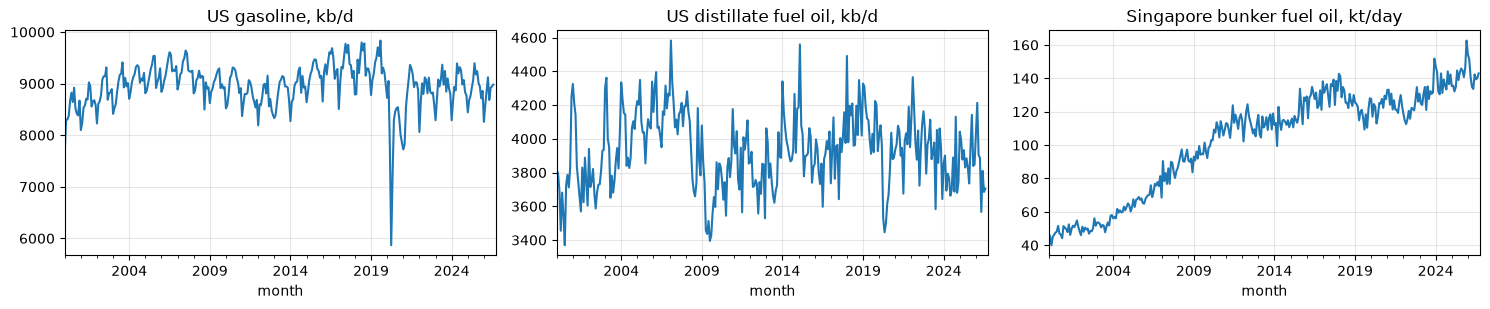

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
titles = {"gasoline": "US gasoline, kb/d", "distillate": "US distillate fuel oil, kb/d", "bunker": "Singapore bunker fuel oil, kt/day"}
for ax, (product, df) in zip(axes, datasets.items()):
    df["demand"].plot(ax=ax, title=titles[product])
    ax.set_xlabel("month")
plt.tight_layout();

**What this dataset is and is not.**

- Every driver value was published by the month end of its row, under release-calendar lags that a real download confirms are not too short.
- It is **not** a vintage dataset. Values are today's, including later revisions; section 5 measures the size of one month of revisions.
- Lags are conventions rounded up to a month end, so some drivers are used up to a month later than they could be. The bias is towards a harder test for the model, not an easier one.
- Nothing was filled or removed. Missing values stay missing; XGBoost handles them natively.

---
The dataset is ready: `python -m src.model` and notebook 02 read `panel` and add no data operation of their own.